# Decision Trees and Ensemble Learning

A single decision tree is easy to read but often overfits. Ensemble methods combine many weak or
unstable models into a stronger predictor. This notebook covers the main families:

- **Bagging** - train many models on bootstrap samples and average them (Random Forest).
- **Boosting** - train models sequentially, each one correcting the errors of the previous ones
  (Gradient Boosting, HistGradientBoosting).
- **Voting** - combine different algorithms by averaging their probabilities or taking a majority vote.
- **Stacking** - train a meta-model on the predictions of several base models.

## Learning objectives

1. Explain Gini impurity, entropy, and why tree depth controls overfitting.
2. Read feature importances from a tree-based model.
3. Compare a single tree, a random forest, and gradient boosting with cross-validation.
4. Combine models with soft voting and stacking.
5. Recognise when ensembles help and when they only add complexity.

## 1. Concepts

### Decision tree

A tree repeatedly splits the feature space to make the target groups purer.

- **Gini impurity**: $1 - \sum_k p_k^2$
- **Entropy**: $-\sum_k p_k \log_2 p_k$
- A split is chosen to maximise the impurity decrease.
- Deep trees have low bias but high variance. `max_depth`, `min_samples_leaf`, and
  `min_samples_split` are the main regularisation controls.
- Trees do not require feature scaling, but they are sensitive to small data changes.

### Random Forest (bagging)

- Builds many trees on bootstrap samples and random feature subsets.
- Averaging reduces variance without increasing bias much.
- Key hyperparameters: `n_estimators`, `max_depth`, `max_features`, `min_samples_leaf`.
- Gives a useful (but slightly biased) feature-importance estimate.

### Gradient Boosting

- Builds trees sequentially; each tree fits the residual errors of the current ensemble.
- Usually stronger than a random forest on tabular data, but easier to overfit and slower to train.
- `learning_rate`, `n_estimators`, and tree depth must be tuned together.
- `HistGradientBoostingClassifier` is a faster, histogram-based implementation.

### Voting and stacking

- **Voting** combines predictions directly. Soft voting averages predicted probabilities.
- **Stacking** trains a meta-model on out-of-fold predictions from the base models.
- Both work best when the base models make different kinds of errors.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Load the data

The breast-cancer dataset is small enough to train many models quickly, which makes it ideal for
comparing ensembles.

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 4. A single decision tree: depth vs overfitting

We sweep `max_depth` and record training and test accuracy. The training score keeps rising while the
test score eventually stops improving - the classic overfitting signature.

In [3]:
depths = range(1, 13)
depth_results = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    depth_results.append({
        "max_depth": depth,
        "train_accuracy": tree.score(X_train, y_train),
        "test_accuracy": tree.score(X_test, y_test),
    })

depth_df = pd.DataFrame(depth_results)
depth_df

,max_depth,train_accuracy,test_accuracy
0,1,0.923077,0.921053
1,2,0.958242,0.894737
2,3,0.975824,0.938596
3,4,0.986813,0.938596
4,5,0.993407,0.921053
5,6,0.997802,0.912281
6,7,1.000000,0.912281
7,8,1.000000,0.912281
8,9,1.000000,0.912281
9,10,1.000000,0.912281


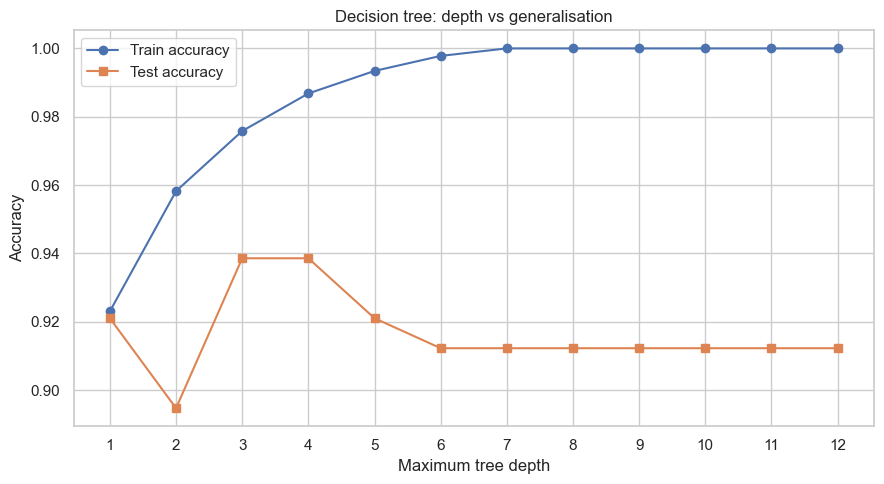

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(depth_df["max_depth"], depth_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(depth_df["max_depth"], depth_df["test_accuracy"], marker="s", label="Test accuracy")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.title("Decision tree: depth vs generalisation")
plt.xticks(list(depths))
plt.legend()
plt.tight_layout()
plt.show()

## 5. Visualising a shallow tree

A depth-3 tree is small enough to read. Each box shows the split rule, impurity, number of samples,
and class distribution.

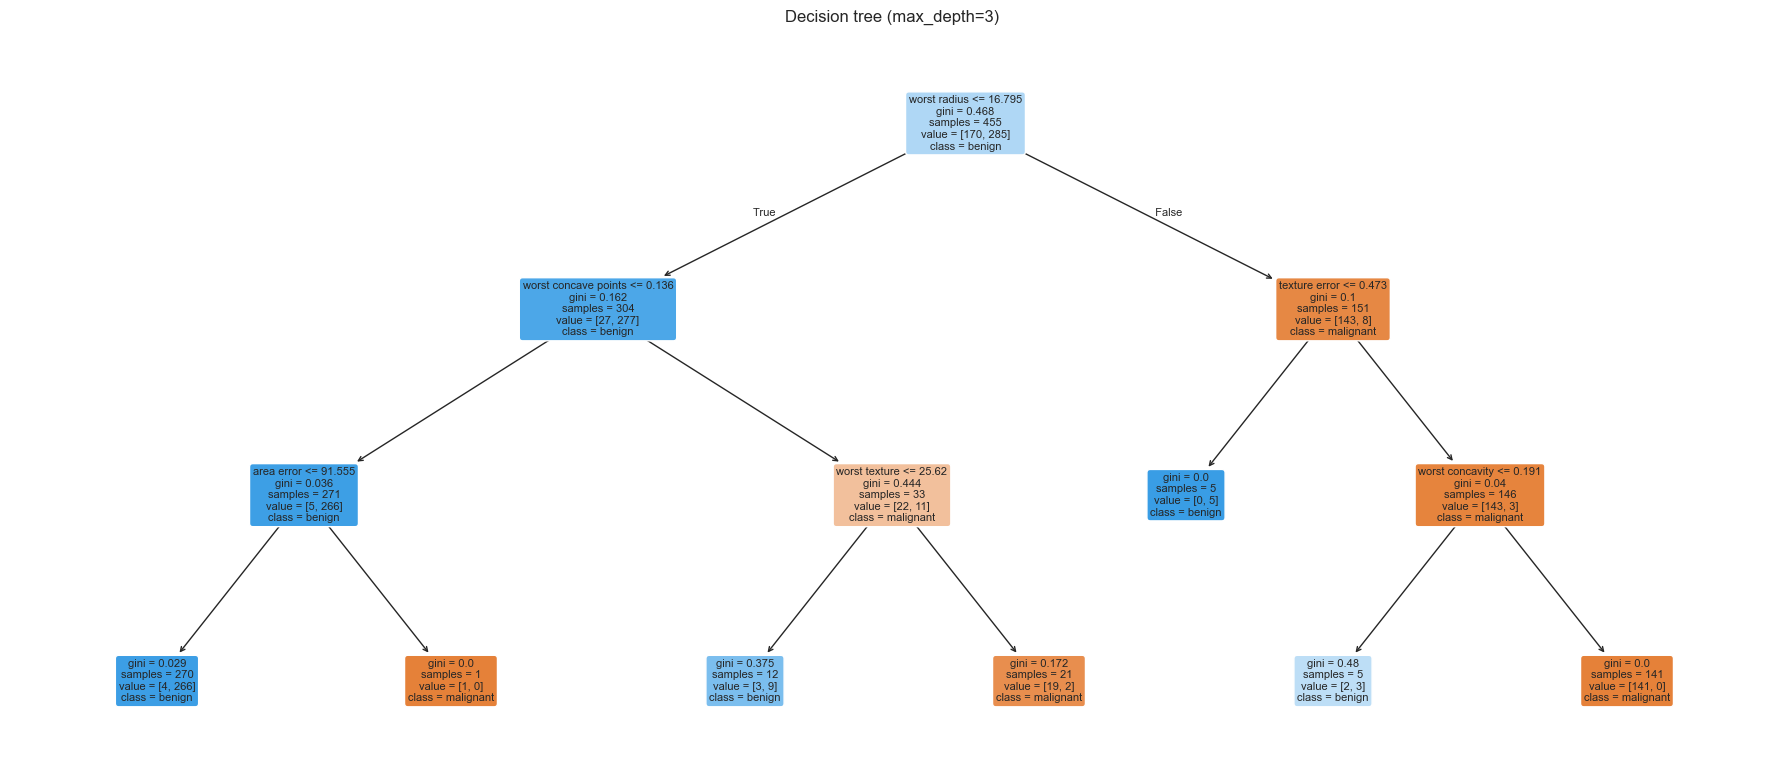

In [5]:
shallow_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
shallow_tree.fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(
    shallow_tree,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("Decision tree (max_depth=3)")
plt.tight_layout()
plt.show()

## 6. Random Forest and Gradient Boosting

We evaluate each model with 5-fold stratified cross-validation on the training set, then confirm the
result on the held-out test set.

In [6]:
models = {
    "Decision Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_features="sqrt", min_samples_leaf=1,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
    model.fit(X_train, y_train)
    test_score = model.score(X_test, y_test)
    rows.append({
        "model": name,
        "cv_mean": cv_scores.mean(),
        "cv_std": cv_scores.std(),
        "test_accuracy": test_score,
    })

pd.DataFrame(rows).sort_values("cv_mean", ascending=False).reset_index(drop=True)

,model,cv_mean,cv_std,test_accuracy
0,Hist Gradient Boosting,0.971429,0.017855,0.973684
1,Random Forest,0.958242,0.022413,0.947368
2,Gradient Boosting,0.958242,0.010767,0.956140
3,Decision Tree (depth=3),0.925275,0.024474,0.938596


## 7. Feature importance

Tree ensembles expose feature importances based on how much each feature reduces impurity. They are
useful for a quick overview, but correlated features can share or hide importance. More reliable
methods (permutation importance) are covered in the interpretability notebook.

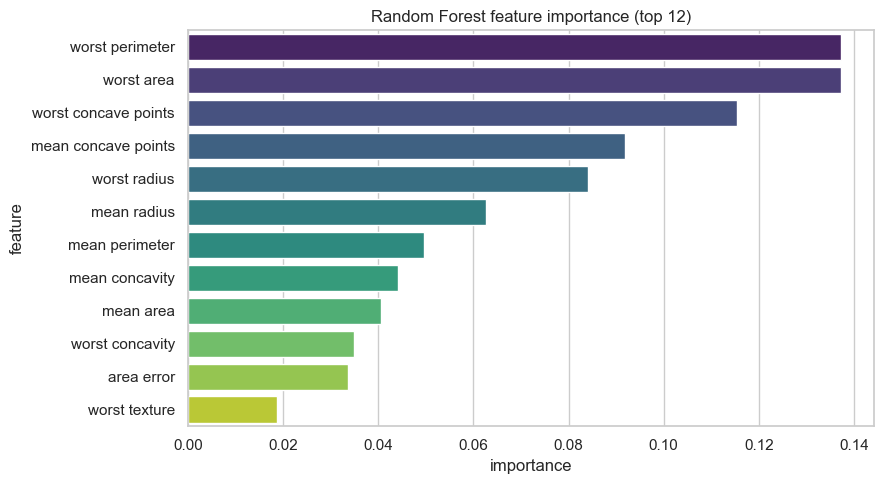

In [7]:
rf = RandomForestClassifier(
    n_estimators=300, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train, y_train)

importance = (
    pd.DataFrame({"feature": X.columns, "importance": rf.feature_importances_})
    .sort_values("importance", ascending=False)
    .head(12)
)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importance (top 12)")
plt.tight_layout()
plt.show()

## 8. Voting and stacking

Soft voting averages predicted probabilities. Stacking uses a logistic-regression meta-model on
out-of-fold predictions. We include a scaled logistic regression as a diverse base model.

In [8]:
logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

voting = VotingClassifier(
    estimators=[
        ("logistic", logistic),
        ("forest", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
        ("boosting", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ],
    voting="soft",
)

stacking = StackingClassifier(
    estimators=[
        ("logistic", logistic),
        ("forest", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
        ("boosting", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ],
    final_estimator=LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    cv=5,
    n_jobs=-1,
)

for name, model in [("Soft voting", voting), ("Stacking", stacking)]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
    model.fit(X_train, y_train)
    print(f"{name}: CV mean={scores.mean():.4f} (+/- {scores.std():.4f}), "
          f"test={model.score(X_test, y_test):.4f}")

Soft voting: CV mean=0.9692 (+/- 0.0176), test=0.9561


Stacking: CV mean=0.9758 (+/- 0.0189), test=0.9737


## 9. Final comparison

A compact table makes the trade-offs visible. On small, clean tabular datasets the gap between
ensembles is often small; on larger or noisier datasets, boosting and random forests usually pull
ahead of a single tree.

In [9]:
comparison = pd.DataFrame(rows)[["model", "cv_mean", "test_accuracy"]].copy()
extra = []
for name, model in [("Soft voting", voting), ("Stacking", stacking)]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
    extra.append({"model": name, "cv_mean": scores.mean(), "test_accuracy": model.score(X_test, y_test)})
comparison = pd.concat([comparison, pd.DataFrame(extra)], ignore_index=True)
comparison.sort_values("cv_mean", ascending=False).reset_index(drop=True)

,model,cv_mean,test_accuracy
0,Stacking,0.975824,0.973684
1,Hist Gradient Boosting,0.971429,0.973684
2,Soft voting,0.969231,0.956140
3,Random Forest,0.958242,0.947368
4,Gradient Boosting,0.958242,0.956140
5,Decision Tree (depth=3),0.925275,0.938596


## Key takeaways

- A single tree is interpretable but unstable; depth is its main complexity control.
- Bagging reduces variance, boosting reduces bias; both can improve accuracy.
- Random forests are a robust default for tabular data.
- Voting and stacking only help when base models are diverse.
- Feature importance from impurity is a starting point, not a causal explanation.
- More complex ensembles cost training time, memory, and interpretability.

## Exercises

1. Tune `n_estimators` and `max_depth` for the random forest with `GridSearchCV`.
2. Replace `GradientBoostingClassifier` with `HistGradientBoostingClassifier` and compare training time.
3. Add a k-nearest-neighbours model to the voting ensemble. Does accuracy improve?
4. Use `permutation_importance` from scikit-learn and compare it with the impurity importances.
5. Explain why stacking needs out-of-fold predictions instead of predictions on the training data.